## Random Forest Classification

In [20]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

### Load and prepare the data

About the dataset

the dataset contains a collection of SMS messages. It was manually extracted from the Grumbletext Web site, this is a UK forum in which cell phone users make public claims about SMS spam messages, most of them without reporting the very spam message received.

Objective: build a random forest classification model that will be able to tell spam messages from ham messages

Goal: create a reliable and user-friendly tool that can accurtely classify a message as either "spam" or "ham"(not spam)

In [2]:
# Load the data
df = pd.read_csv(r"emails.csv")

In [3]:
# inspect by displaying first few rows
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [5]:
# inspect by displaying first few rows
df = df.drop(columns = "Email No.")

In [6]:
# get the total number of columns and rows
df.shape

(5172, 3001)

In [7]:
# get an overview of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3001 entries, the to Prediction
dtypes: int64(3001)
memory usage: 118.4 MB


In [13]:
# check for duplicates
df.duplicated(subset=df.columns.difference(["Prediction"])).sum()

np.int64(0)

In [12]:
# drop duplicates
df = df.drop_duplicates()

### Data preprocessing

In [14]:
#seperate the dataset into independent and target variables
X = df.drop(columns = ["Prediction"])
y = df["Prediction"]

# encode the labels
# y = y.map({"ham": 0, "spam": 1})

In [15]:
# check class imbalance
y.value_counts()

Prediction
0    3170
1    1461
Name: count, dtype: int64

In [16]:
# data splitting into training and testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(3704, 3000) (927, 3000) (3704,) (927,)


In [17]:
X.shape

(4631, 3000)

### Handle class imbalance
using SMOTE TO synthesize new instances of the minority class
and including all in a pipeline to avoid data leakage

In [21]:
rf_pipeline = ImbPipeline([
("tfidf", TfidfTransformer()),
("sampler", SMOTE(random_state = 42)),
("classifier", RandomForestClassifier(random_state = 42))])

### Hyperparameter tuning and model training
Randomized search technique

unlike grid search that creates every possible combination of hyperparameters, Randomized search samples a fixed number (n_iter) of random combinations from the specified parameter distribution. it is faster and more efficient than its counterpart

In [22]:
# list of hyperparameters and their respective range of values (grid definition)
param_distributions = {
    "sampler__k_neighbors": [3, 5],
    "classifier__max_depth": [3, 5, 10, None],  
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4, 8],
    "classifier__n_estimators": [50, 100, 200] 
}

The model is trained and evaluated multiple times (cross validation) for a fixed number of combination of hyperparameters and the set of hyperparameters that results in the highest average-precision score is selected

In [23]:
random_search = RandomizedSearchCV(estimator = rf_pipeline, param_distributions = param_distributions, scoring = "average_precision", n_iter = 50, cv = StratifiedKFold(n_splits=3), n_jobs = -1, verbose = 2, random_state = 42)
print("Starting randomized search\n")
random_search.fit(X_train, y_train)
print("Randomized search complete\n")
print("best parameters are:\n", random_search.best_params_)
print("best score:", random_search.best_score_)

Starting randomized search

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Randomized search complete

best parameters are:
 {'sampler__k_neighbors': 3, 'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': None}
best score: 0.9770761302368691


The final model trained using the best hyperparameters on the entire training set is stored in the grid_search.best_estimator attribute, this is the model used for making predictions and its overall performance is evaluated

In [24]:
best_model = random_search.best_estimator_

### Model Testing

In [27]:
y_pred = best_model.predict(X_test)

### Model Evaluation¶

In [28]:
accuracy = accuracy_score(y_test, y_pred)

print(f"accuracy: {accuracy:.2f}")

accuracy: 0.98


In [29]:
precision = precision_score(y_test, y_pred)

print(f"precision: {precision:.2f}")

precision: 0.95


In [30]:
recall = recall_score(y_test, y_pred)

print(f"recall: {recall:.2f}")

recall: 0.98


#### confusion matrix

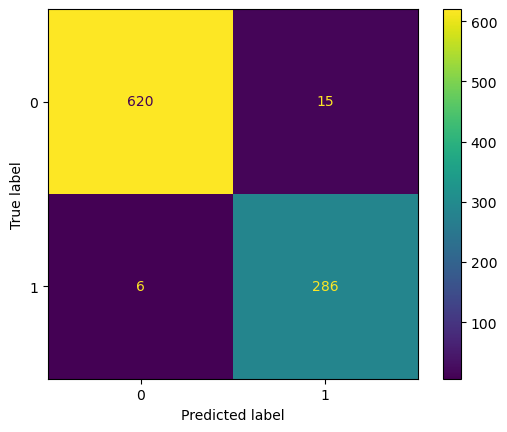

In [31]:
cm = confusion_matrix(y_test, y_pred)
matrix = ConfusionMatrixDisplay(cm, display_labels = best_model.classes_)
matrix.plot()

#### classification report

In [32]:
cr = classification_report(y_test, y_pred, output_dict = True)

Text(0.5, 1.0, 'Classification Report Heatmap')

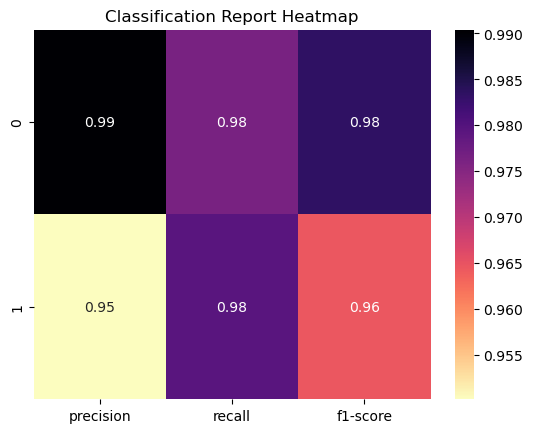

In [33]:
# to get a clearer picture
cr = classification_report(y_test, y_pred, output_dict = True)
cr_df = pd.DataFrame(cr).transpose()
sns.heatmap(cr_df.iloc[:-3, :].drop("support", axis = 1), annot = True, fmt = ".2f", cmap = "magma_r")
plt.title("Classification Report Heatmap")

In [39]:
import streamlit as st
import joblib
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline

### Build a pipeline that converts texts entered by users to numerical values the model can process

In [40]:
# Extract the exact 3,000 feature names in order
vocab = list(X_train.columns)

# Initialize CountVectorizer locked to those exact 3,000 words
vectorizer = CountVectorizer(vocabulary=vocab, lowercase=True)

# Extract the trained classifier from your best_model
trained_clf = best_model.named_steps["classifier"]

# Combine them into a final text-to-prediction pipeline
final_text_pipeline = Pipeline([
    ("vectorizer", vectorizer),
    ("classifier", trained_clf)
])

# Save the text-ready pipeline for Streamlit
joblib.dump(final_text_pipeline, "best_pipeline.pkl")

['best_pipeline.pkl']

In [36]:
import json

In [37]:
with open("model_metrics.json", "w") as f:
    json.dump(cr, f)